<h1 style="text-align: center;">ETTh2 Transformer Temperature Tracker</strong>

<div style="position: relative; text-align: center;">
  <strong style="position: absolute; left: 0;">Authors:</strong>
  Jan Wodnicki · Jacob Isho · James Gilbank
</div>

### ETTH2 dataset

#### Raw Data Preview

In [1]:
# Initial setup required for loading the CSV file and plotting the data.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Load the CSV from the same folder as this notebook.
df = pd.read_csv("ETTh2.csv", parse_dates=["date"])

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()

Loaded 17,420 rows and 8 columns.


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001
2,2016-07-01 02:00:00,37.946999,11.309,35.330002,9.007,2.100,0.000,36.465000
3,2016-07-01 03:00:00,38.952000,11.895,35.543999,9.436,3.380,1.215,33.608501
4,2016-07-01 04:00:00,38.113998,11.476,35.410000,9.623,2.036,0.000,31.850500


The table below explains the acronyms used inside the dataset:

| **HUFL** | **HULL** | **MUFL** | **MULL** | **LUFL** | **LULL** | **OT** |
|----------|----------|----------|----------|----------|----------|--------|
| High Useful Load | High Useless Load | Middle Useful Load | Middle Useless Load | Low Useful Load | Low Useless Load | Oil Temperature |

**Prediction target:** `OT` represents the transformer's oil temperature, which we aim to predict using the changing load measurements.

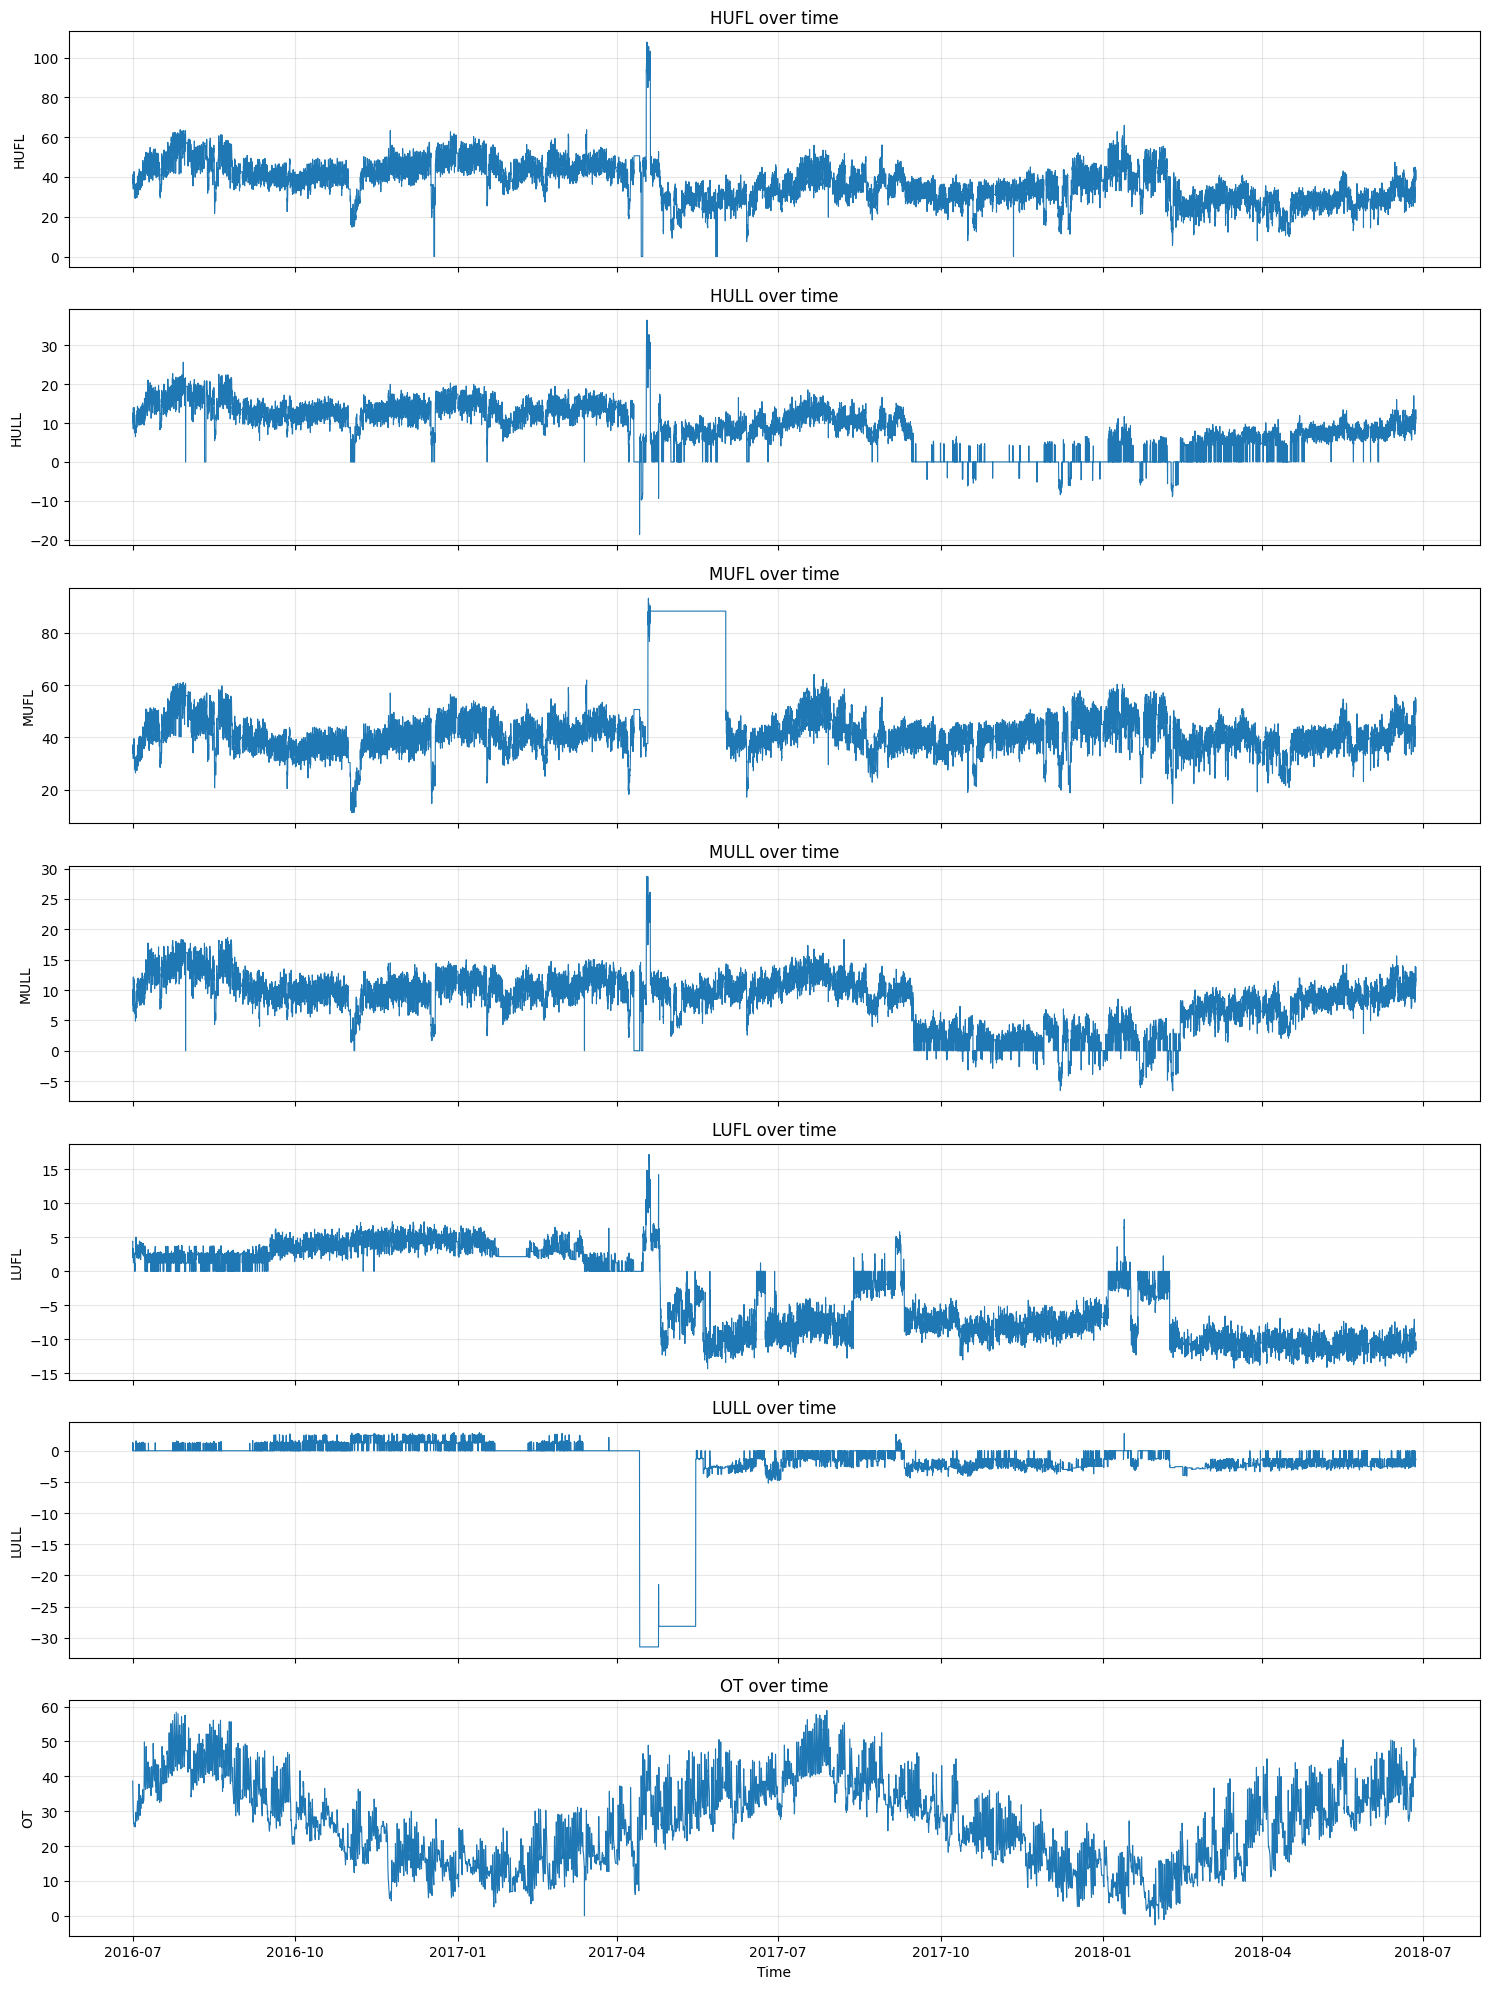

In [2]:
# Plot all variables over time.

variables = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]

fig, axes = plt.subplots(7, 1, figsize=(15, 20), sharex=True)

for ax, variable in zip(axes, variables):
    ax.plot(df["date"], df[variable], linewidth=0.8)
    ax.set_title(f"{variable} over time")
    ax.set_ylabel(variable)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

#### Preprocessing and Data Split

In [3]:
data = df.copy()

# Validate timestamps and put observations in chronological order.
data["date"] = pd.to_datetime(data["date"], errors="coerce")

if data["date"].isna().any():
    raise ValueError("Missing or invalid timestamps must be corrected first.")

data = data.sort_values("date").set_index("date")

# Convert measurements to numbers; treat invalid/infinite values as missing.
variables = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]
data[variables] = (
    data[variables]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

# Report missing values and drop any affected measurement columns.
missing_counts = data[variables].isna().sum()
print("Missing values per column:")
print(missing_counts)

columns_to_drop = missing_counts[missing_counts > 0].index.tolist()
data = data.drop(columns=columns_to_drop)
print("\nDropped columns:", columns_to_drop or "None")

if "OT" in columns_to_drop:
    print("WARNING: OT was dropped; it is needed for temperature prediction.")


# Using the 60/20/20 split for training, validation, and testing.
# This was defined inside the project description requirements.
n = len(data)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = data.iloc[:train_end].copy()
val_raw   = data.iloc[train_end:val_end].copy()
test_raw  = data.iloc[val_end:].copy()

for name, split in [
    ("Train", train_raw),
    ("Val", val_raw),
    ("Test", test_raw),
]:
    print(
        f"{name:5}: {len(split):,} rows | "
        f"{split.index.min()} to {split.index.max()}"
    )


Missing values per column:
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64

Dropped columns: None
Train: 10,452 rows | 2016-07-01 00:00:00 to 2017-09-09 11:00:00
Val  : 3,484 rows | 2017-09-09 12:00:00 to 2018-02-01 15:00:00
Test : 3,484 rows | 2018-02-01 16:00:00 to 2018-06-26 19:00:00


#### Oil Temperature Data Split Visualized

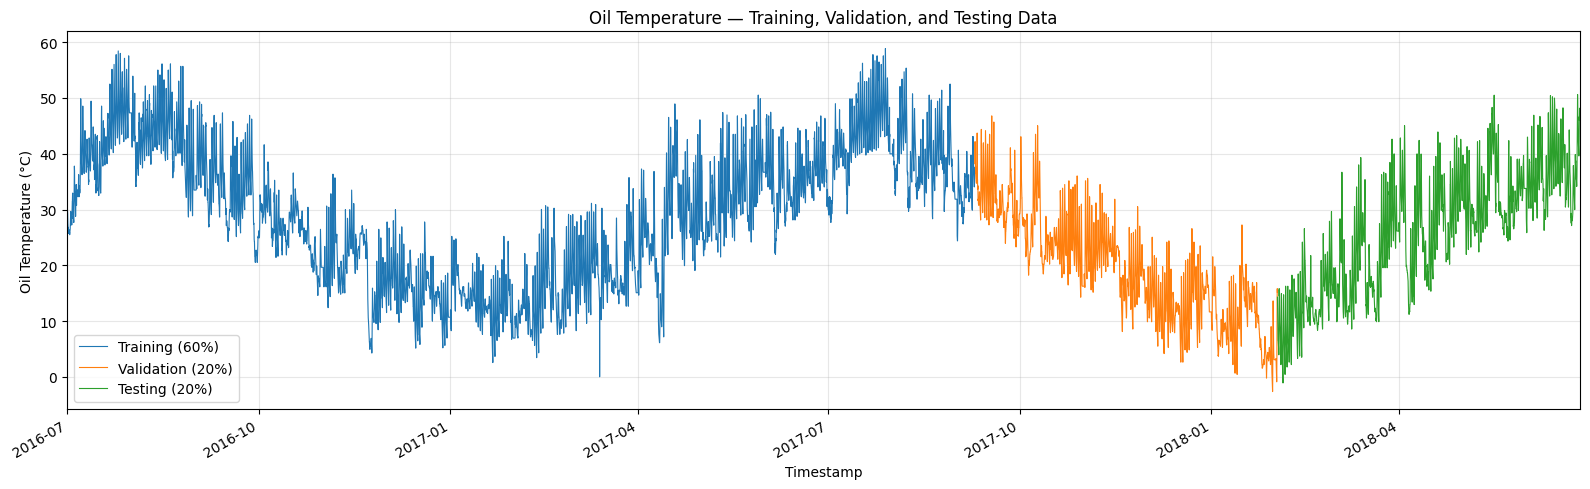

In [4]:
# Oil Temperature split plot visualization
fig, ax = plt.subplots(figsize=(16, 5))

for label, split, color in [
    ("Training (60%)", train_raw, "tab:blue"),
    ("Validation (20%)", val_raw, "tab:orange"),
    ("Testing (20%)", test_raw, "tab:green"),
]:
    ax.plot(
        split.index,
        split["OT"],
        color=color,
        label=label,
        linewidth=0.8,
    )

ax.set(
    title="Oil Temperature — Training, Validation, and Testing Data",
    xlabel="Timestamp",
    ylabel="Oil Temperature (°C)",
    xlim=(train_raw.index.min(), test_raw.index.max()),
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()



#### Normalized Data

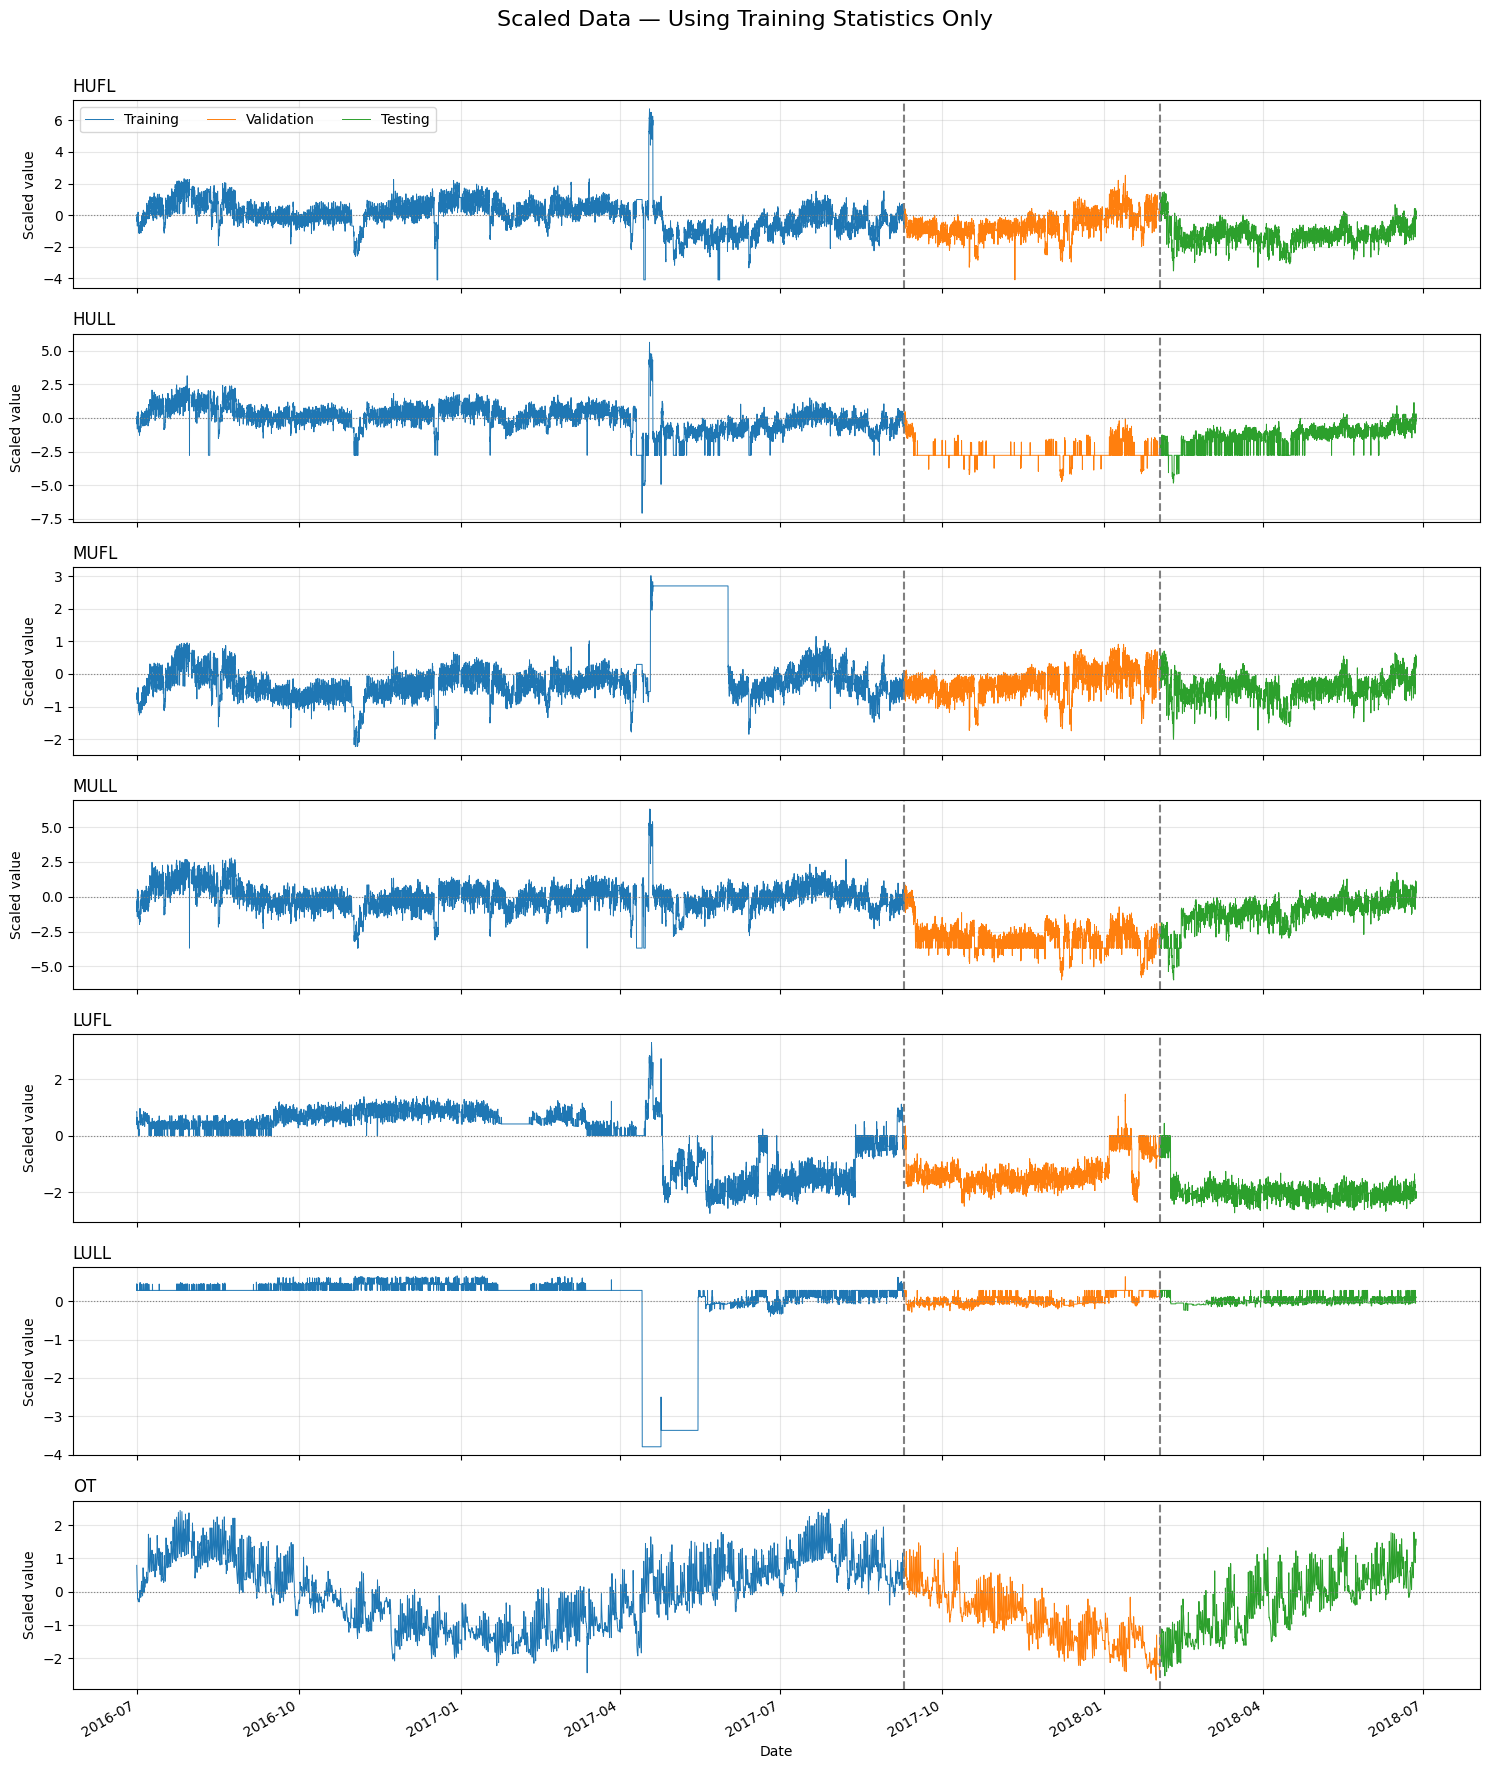

In [5]:
# Calculate scaling parameters from training data only.
train_mean = train_raw.mean()
train_std = train_raw.std()

# Avoid division by zero for constant columns.
train_std = train_std.replace(0, 1)

# Apply the SAME parameters to all three splits.
train_scaled = (train_raw - train_mean) / train_std
val_scaled = (val_raw - train_mean) / train_std
test_scaled = (test_raw - train_mean) / train_std


# Inspect training statistics.
# print("Scaled training statistics:")

# print(pd.DataFrame({
#    "Mean": train_scaled.mean(),
#    "Standard deviation": train_scaled.std(),
# }).round(4))

# Convert scaled OT predictions back to the original temperature units.
def inverse_scale_ot(predictions):
    return np.asarray(predictions) * train_std["OT"] + train_mean["OT"]


# Plot the scaled data for all three splits.
import matplotlib.pyplot as plt

variables = train_scaled.columns

fig, axes = plt.subplots(
    len(variables), 1,
    figsize=(15, 18),
    sharex=True,
    squeeze=False,
)

for ax, variable in zip(axes[:, 0], variables):
    for label, split, color in [
        ("Training", train_scaled, "tab:blue"),
        ("Validation", val_scaled, "tab:orange"),
        ("Testing", test_scaled, "tab:green"),
    ]:
        ax.plot(
            split.index, split[variable],
            label=label, color=color, linewidth=0.7,
        )

    ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
    ax.axvline(val_scaled.index[0], color="gray", linestyle="--")
    ax.axvline(test_scaled.index[0], color="gray", linestyle="--")
    ax.set_title(variable, loc="left")
    ax.set_ylabel("Scaled value")
    ax.grid(True, alpha=0.3)

axes[0, 0].legend(ncol=3)
axes[-1, 0].set_xlabel("Date")

fig.suptitle("Scaled Data — Using Training Statistics Only", fontsize=16)
fig.autofmt_xdate()
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


#### Stationarity?


### Stage 1 - Baseline and Traditional ML Models


#### Baselines


##### Seasonal Naive



To establish a seasonal naive the assumption is that the seasonality of the data has a lag of 24, relating to the difference of Oil Temperature 24 hours apart. The SN model, visually appears to map itself quite well with the testing data, and has an MAE of 3.53°C and an RMSE of 4.77°C of error. These values are respectable baseline to contrast more sophisticated model architectures.

Daily seasonal naive performance:
               MAE    RMSE
Split                     
Validation  2.8193  3.8180
Testing     3.5256  4.7721


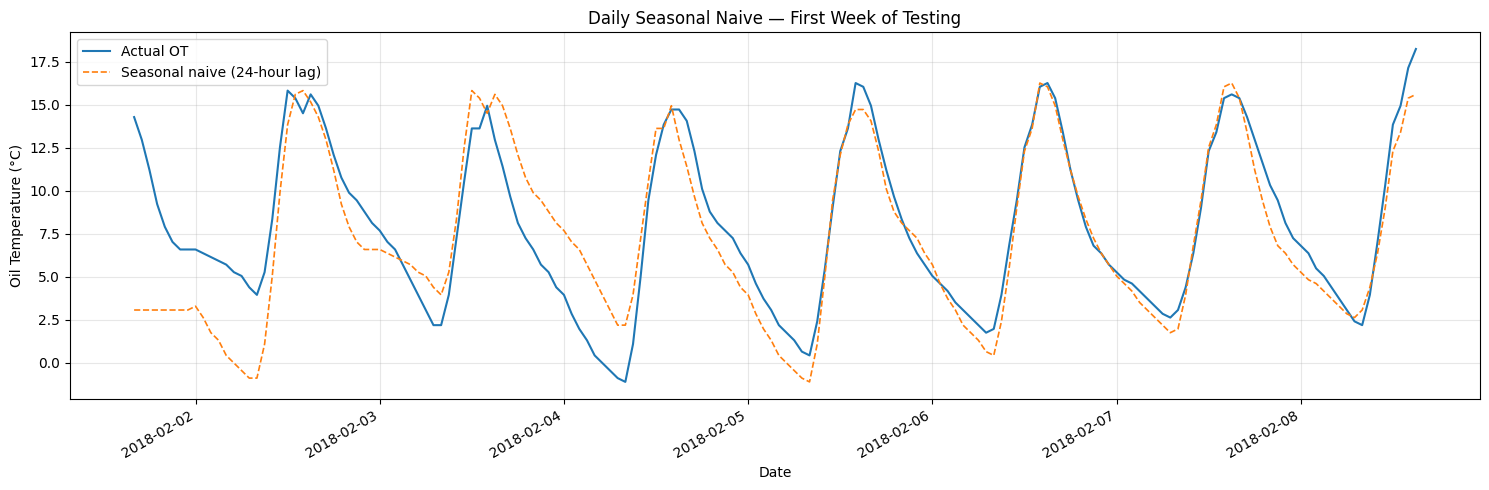

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seasonal_period = 24  # Hourly data: 24 = daily, 168 = weekly

# Include past observations across split boundaries.
ot = pd.concat([
    train_raw["OT"],
    val_raw["OT"],
    test_raw["OT"],
])

seasonal_predictions = ot.shift(seasonal_period)

# Evaluate validation and test predictions.
results = []

for name, split in [
    ("Validation", val_raw),
    ("Testing", test_raw),
]:
    actual = split["OT"]
    predicted = seasonal_predictions.reindex(actual.index)

    if predicted.isna().any():
        raise ValueError("Insufficient history for the seasonal period.")

    errors = actual - predicted

    results.append({
        "Split": name,
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    })

print("Daily seasonal naive performance:")
print(pd.DataFrame(results).set_index("Split").round(4))

# Display the first seven days of testing.
actual = test_raw["OT"].iloc[:168]
predicted = seasonal_predictions.reindex(actual.index)

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(actual.index, actual, label="Actual OT", linewidth=1.5)
ax.plot(
    predicted.index, predicted,
    label="Seasonal naive (24-hour lag)",
    linestyle="--", linewidth=1.2,
)

ax.set(
    title="Daily Seasonal Naive — First Week of Testing",
    xlabel="Date",
    ylabel="Oil Temperature (°C)",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

##### Mean

To establish the mean baseline, the average Oil Temperature was calculated from the training data. It was then plotted against the first week of the testing data, where it shows how a fixed prediction is uneffective at predicting the Oil Temperatures which changes throughout the year. The results display an MAE of 9.02°C and an RMSE of 11.41 °C of error, showing the unreliability of this prediction model.

Training mean OT: 29.1780 °C

Mean baseline performance:
                MAE     RMSE
Split                       
Validation  11.3894  13.6091
Testing      9.0242  11.1410


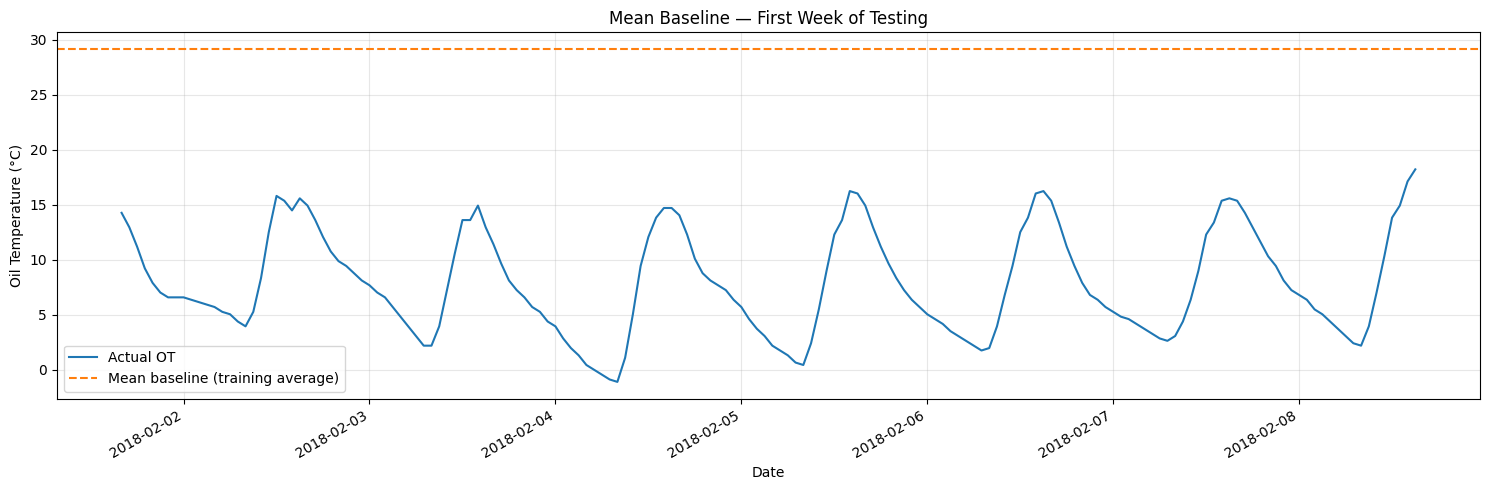

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the baseline using training data only.
mean_ot = train_raw["OT"].mean()

results = []

for name, split in [
    ("Validation", val_raw),
    ("Testing", test_raw),
]:
    actual = split["OT"]
    predicted = np.full(len(actual), mean_ot)
    errors = actual - predicted

    results.append({
        "Split": name,
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    })

print(f"Training mean OT: {mean_ot:.4f} °C")
print("\nMean baseline performance:")
print(pd.DataFrame(results).set_index("Split").round(4))

# Display the first seven days of testing.
actual = test_raw["OT"].iloc[:168]

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(actual.index, actual, label="Actual OT", linewidth=1.5)
ax.axhline(
    mean_ot,
    label="Mean baseline (training average)",
    color="tab:orange",
    linestyle="--",
    linewidth=1.5,
)

ax.set(
    title="Mean Baseline — First Week of Testing",
    xlabel="Date",
    ylabel="Oil Temperature (°C)",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### Model Setup

In [8]:
import os, time, json, itertools
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

SEED = 42
keras.utils.set_random_seed(SEED)  # seeds python, numpy and tensorflow
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

LOOKBACK = 96   # hours of history fed to the model
HORIZON = 24    # hours ahead to forecast
FEATURES = list(train_scaled.columns)
TARGET = 'OT'
OT_IDX = FEATURES.index(TARGET)
N_FEATURES = len(FEATURES)

# Stack the already-scaled splits so val/test windows can look back into earlier data.
full_scaled = pd.concat([train_scaled, val_scaled, test_scaled])
X_all = full_scaled[FEATURES].to_numpy(dtype=np.float32)
y_all = full_scaled[TARGET].to_numpy(dtype=np.float32)
times_all = full_scaled.index

n_train, n_val = len(train_scaled), len(val_scaled)
split_ranges = {
    'Train': (0, n_train),
    'Val': (n_train, n_train + n_val),
    'Test': (n_train + n_val, len(full_scaled)),
}

def make_windows(start, end):
    # Input rows [t - LOOKBACK, t), target OT rows [t, t + HORIZON), all targets inside [start, end).
    starts = np.arange(max(start, LOOKBACK), end - HORIZON + 1)
    X = np.stack([X_all[t - LOOKBACK:t] for t in starts])
    y = np.stack([y_all[t:t + HORIZON] for t in starts])
    return X, y, starts

X_train, y_train, t_train = make_windows(*split_ranges['Train'])
X_val, y_val, t_val = make_windows(*split_ranges['Val'])
X_test, y_test, t_test = make_windows(*split_ranges['Test'])

window_table = pd.DataFrame({
    'X shape (windows, lookback, features)': [X_train.shape, X_val.shape, X_test.shape],
    'y shape (windows, horizon)': [y_train.shape, y_val.shape, y_test.shape],
    'First target time': [times_all[t[0]] for t in (t_train, t_val, t_test)],
    'Last target time': [times_all[t[-1] + HORIZON - 1] for t in (t_train, t_val, t_test)],
}, index=['Train', 'Val', 'Test'])
display(window_table)

# Alignment check on the first validation window.
t0 = t_val[0]
print(f'First val window input : {times_all[t0 - LOOKBACK]} -> {times_all[t0 - 1]}')
print(f'First val window target: {times_all[t0]} -> {times_all[t0 + HORIZON - 1]}')
assert t_train[-1] + HORIZON <= n_train, 'Training targets leak into validation'
assert t_val[-1] + HORIZON <= n_train + n_val, 'Validation targets leak into test'

,"X shape (windows, lookback, features)","y shape (windows, horizon)",First target time,Last target time
Train,"(10333, 96, 7)","(10333, 24)",2016-07-05 00:00:00,2017-09-09 11:00:00
Val,"(3461, 96, 7)","(3461, 24)",2017-09-09 12:00:00,2018-02-01 15:00:00
Test,"(3461, 96, 7)","(3461, 24)",2018-02-01 16:00:00,2018-06-26 19:00:00


First val window input : 2017-09-05 12:00:00 -> 2017-09-09 11:00:00
First val window target: 2017-09-09 12:00:00 -> 2017-09-10 11:00:00


In [9]:
# Metrics (in °C)
def to_celsius(a):
    return inverse_scale_ot(a)

def score(y_true_scaled, y_pred_scaled):
    err = to_celsius(y_true_scaled) - to_celsius(y_pred_scaled)
    return {'MAE': float(np.mean(np.abs(err))), 'RMSE': float(np.sqrt(np.mean(err ** 2)))}

# Baselines re-scored on the exact same windows
assert HORIZON <= 24, 'Seasonal naive below assumes a horizon of at most one day'

def seasonal_naive(X):
    # OT 24 h before each target hour = OT at the end of the input window.
    return X[:, LOOKBACK - 24:LOOKBACK - 24 + HORIZON, OT_IDX]

# Results table shared by all models
comparison_rows = []

def add_result(name, params, train_time, inf_ms, val_pred, test_pred, epochs=None):
    comparison_rows[:] = [r for r in comparison_rows if r['Model'] != name]  # safe to re-run
    v, te = score(y_val, val_pred), score(y_test, test_pred)
    comparison_rows.append({
        'Model': name, 'Params': params, 'Epochs': epochs,
        'Train time (s)': train_time, 'Inference (ms/window)': inf_ms,
        'Val MAE': v['MAE'], 'Val RMSE': v['RMSE'],
        'Test MAE': te['MAE'], 'Test RMSE': te['RMSE'],
    })

def comparison_table():
    table = pd.DataFrame(comparison_rows).set_index('Model')
    sn = table.loc['Seasonal naive (24 h)']
    table['Val MAE gain vs SN (%)'] = 100 * (1 - table['Val MAE'] / sn['Val MAE'])
    table['Test MAE gain vs SN (%)'] = 100 * (1 - table['Test MAE'] / sn['Test MAE'])
    return table.round(3)

# Scaled training mean of OT is 0, so the mean baseline is a vector of zeros.
add_result('Seasonal naive (24 h)', 0, 0.0, 0.0, seasonal_naive(X_val), seasonal_naive(X_test))
add_result('Train mean', 1, 0.0, 0.0, np.zeros_like(y_val), np.zeros_like(y_test))

# Training / evaluation
def fit_model(build_fn, lr=1e-3, batch_size=64, epochs=100, patience=10, verbose=0, **arch):
    keras.utils.set_random_seed(SEED)  # same initialisation and batch order for every run
    model = build_fn(**arch)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    early = keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                          restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size, shuffle=True,
                        callbacks=[early], verbose=verbose)
    return model, history, time.perf_counter() - start

def predict_timed(model, X):
    start = time.perf_counter()
    pred = model.predict(X, batch_size=1024, verbose=0)
    return pred, (time.perf_counter() - start) * 1000 / len(X)

def evaluate_model(name, model, history, train_time):
    val_pred, _ = predict_timed(model, X_val)
    test_pred, inf_ms = predict_timed(model, X_test)
    add_result(name, model.count_params(), train_time, inf_ms, val_pred, test_pred,
               epochs=len(history.history['loss']))
    return val_pred, test_pred

# Plots
def plot_learning_curves(history, title):
    best = int(np.argmin(history.history['val_loss']))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, key, label in [(axes[0], 'loss', 'MSE loss (scaled)'), (axes[1], 'mae', 'MAE (scaled)')]:
        ax.plot(history.history[key], label='Train')
        ax.plot(history.history['val_' + key], label='Validation')
        ax.axvline(best, color='gray', linestyle='--', label=f'Best epoch ({best + 1})')
        ax.set(title=f'{title} — {label}', xlabel='Epoch', ylabel=label)
        ax.grid(True, alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

def plot_forecasts(test_pred, title, days=7):
    n = days * 24
    target_times = times_all[t_test[:n] + HORIZON - 1]
    sn_test = seasonal_naive(X_test)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [2, 1]})

    # Left: the 24-hour-ahead forecast (last output) against the actual OT.
    axes[0].plot(target_times, to_celsius(y_test[:n, -1]), label='Actual OT', linewidth=1.5)
    axes[0].plot(target_times, to_celsius(sn_test[:n, -1]), '--', label='Seasonal naive', linewidth=1)
    axes[0].plot(target_times, to_celsius(test_pred[:n, -1]), label=title, linewidth=1.2)
    axes[0].set(title=f'{title} — 24 h-ahead forecast, first {days} days of test',
                xlabel='Date', ylabel='Oil Temperature (°C)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Right: how error grows with the forecast step.
    steps = np.arange(1, HORIZON + 1)
    mae_model = np.mean(np.abs(to_celsius(y_test) - to_celsius(test_pred)), axis=0)
    mae_sn = np.mean(np.abs(to_celsius(y_test) - to_celsius(sn_test)), axis=0)
    axes[1].plot(steps, mae_model, marker='o', markersize=3, label=title)
    axes[1].plot(steps, mae_sn, '--', label='Seasonal naive')
    axes[1].set(title='Test MAE by forecast step', xlabel='Hours ahead', ylabel='MAE (°C)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

display(comparison_table())

,Params,Epochs,Train time (s),Inference (ms/window),Val MAE,Val RMSE,Test MAE,Test RMSE,Val MAE gain vs SN (%),Test MAE gain vs SN (%)
Model,,,,,,,,,,
Seasonal naive (24 h),0,None,0.0,0.0,2.816,3.807,3.520,4.770,0.000,0.000
Train mean,1,None,0.0,0.0,11.359,13.575,8.963,11.074,-303.435,-154.607


In [10]:
def normalize_window(inputs):
    last = inputs[:, -1:, :]                    # (batch, 1, features)
    last_ot = last[:, 0, OT_IDX:OT_IDX + 1]     # (batch, 1)
    return inputs - last, last_ot

### MLP Model
The MLP flattens each 96 × 7 window into one 672-value vector, so it has no built-in sense of time order, every lag of every variable is just another input. Two ReLU hidden layers with dropout feed a linear 24-unit output (one unit per forecast hour). This is the simplest neural model and the reference the CNN has to beat.

In [11]:
def build_mlp(hidden=(128, 64), dropout=0.2):
    inputs = keras.Input(shape=(LOOKBACK, N_FEATURES))
    x, last_ot = normalize_window(inputs)
    x = layers.Flatten()(x)
    for units in hidden:
        x = layers.Dense(units, activation='relu')(x)
        x = layers.Dropout(dropout)(x)
    delta = layers.Dense(HORIZON)(x)            # predicted change from the last OT
    outputs = delta + last_ot
    return keras.Model(inputs, outputs, name='MLP')

MLP_CONFIG = {'hidden': (128, 64), 'dropout': 0.2, 'lr': 1e-3, 'batch_size': 64}

mlp, mlp_hist, mlp_time = fit_model(build_mlp, **MLP_CONFIG)
mlp.summary()

mlp_val_pred, mlp_test_pred = evaluate_model('MLP', mlp, mlp_hist, mlp_time)
mlp_epochs = len(mlp_hist.history['loss'])
mlp_best = int(np.argmin(mlp_hist.history['val_loss'])) + 1
print(f'MLP: {mlp_epochs} epochs (best {mlp_best}), {mlp_time:.1f} s')
display(comparison_table())

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 1, 7)      │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 96, 7)     │          0 │ input_layer[0][0… │
│                     │                   │            │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 672)       │          0 │ subtract[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     86,144 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 24)        │      1,560 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 1)         │          0 │ get_item[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24)        │          0 │ dense_2[0][0],    │
│                     │                   │            │ get_item_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 287,882 (1.10 MB)

 Trainable params: 95,960 (374.84 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 191,922 (749.70 KB)

MLP: 16 epochs (best 6), 8.8 s


,Params,Epochs,Train time (s),Inference (ms/window),Val MAE,Val RMSE,Test MAE,Test RMSE,Val MAE gain vs SN (%),Test MAE gain vs SN (%)
Model,,,,,,,,,,
Seasonal naive (24 h),0,NaN,0.000,0.000,2.816,3.807,3.520,4.770,0.000,0.000
Train mean,1,NaN,0.000,0.000,11.359,13.575,8.963,11.074,-303.435,-154.607
MLP,95960,16.0,8.832,0.029,2.376,3.223,2.848,4.016,15.597,19.090


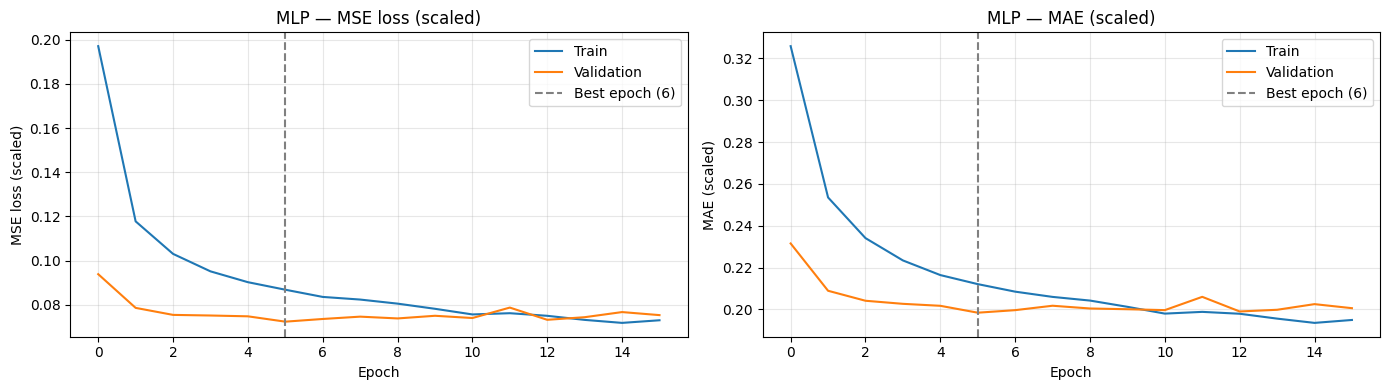

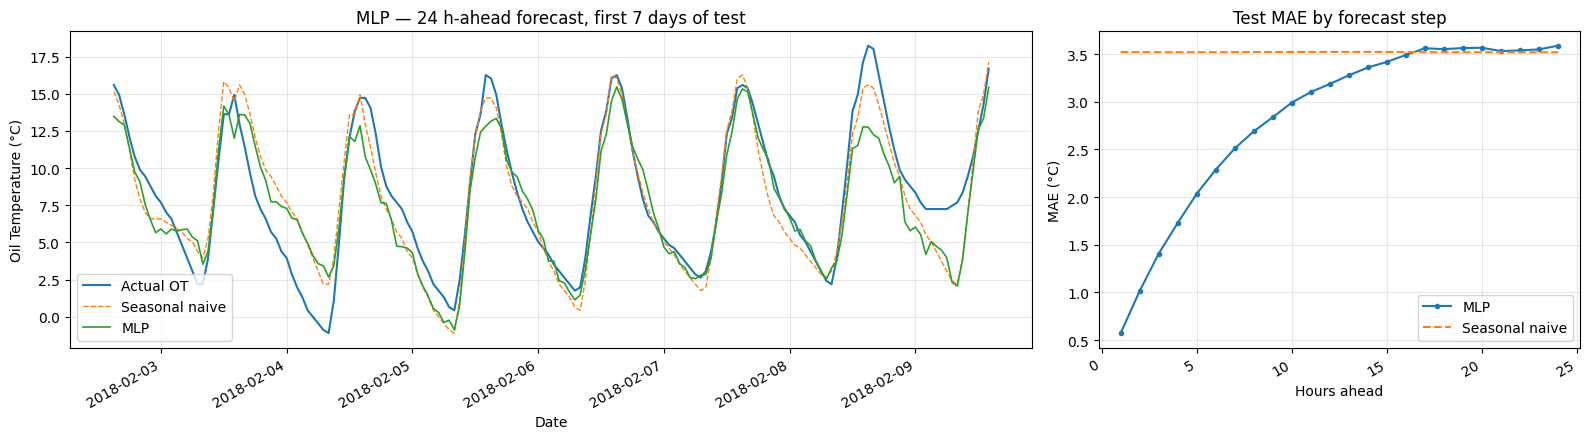

In [12]:
# MLP learning curves and test forecasts.
plot_learning_curves(mlp_hist, 'MLP')
plot_forecasts(mlp_test_pred, 'MLP')

The MLP beats the seasonal naive by 19% test MAE, but the gain is all in the first ~15 hours. Beyond 16 h it matches the seasonal naive, and it under-predicts unusually high peaks.

#### CNN Model
The CNN slides small 1-D filters along the time axis, so the same pattern detector (for example, a load ramp followed by a temperature rise) is reused at every position in the window. Causal padding means each convolution only sees the current and earlier hours. Each block doubles the filters and max-pools to halve the time axis (96 -> 48 -> 24). The two conv layers only have about 11k weights; most of the CNN’s 111k parameters are in the dense layer after Flatten. It uses the same last-value normalisation, optimiser, loss and stopping rule as the MLP, so the two are compared fairly.

In [13]:
def build_cnn(filters=32, kernel_size=5, n_blocks=2, dropout=0.2, dense_units=64):
    inputs = keras.Input(shape=(LOOKBACK, N_FEATURES))
    x, last_ot = normalize_window(inputs)
    for i in range(n_blocks):
        x = layers.Conv1D(filters * 2 ** i, kernel_size, padding='causal', activation='relu')(x)
        x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    delta = layers.Dense(HORIZON)(x)            # predicted change from the last OT
    outputs = delta + last_ot
    return keras.Model(inputs, outputs, name='CNN')

CNN_CONFIG = {'filters': 32, 'kernel_size': 5, 'n_blocks': 2, 'dropout': 0.2,
              'lr': 1e-3, 'batch_size': 64}

cnn, cnn_hist, cnn_time = fit_model(build_cnn, **CNN_CONFIG)
cnn.summary()

cnn_val_pred, cnn_test_pred = evaluate_model('CNN', cnn, cnn_hist, cnn_time)
cnn_epochs = len(cnn_hist.history['loss'])
cnn_best = int(np.argmin(cnn_hist.history['val_loss'])) + 1
print(f'CNN: {cnn_epochs} epochs (best {cnn_best}), {cnn_time:.1f} s')
display(comparison_table())

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 96, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 1, 7)      │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract_1          │ (None, 96, 7)     │          0 │ input_layer_1[0]… │
│ (Subtract)          │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 96, 32)    │      1,152 │ subtract_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 48, 32)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 48, 64)    │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 24, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1536)      │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │     98,368 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 24)        │      1,560 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 1)         │          0 │ get_item_2[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24)        │          0 │ dense_4[0][0],    │
│                     │                   │            │ get_item_3[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 334,154 (1.27 MB)

 Trainable params: 111,384 (435.09 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 222,770 (870.20 KB)

CNN: 12 epochs (best 2), 26.0 s


,Params,Epochs,Train time (s),Inference (ms/window),Val MAE,Val RMSE,Test MAE,Test RMSE,Val MAE gain vs SN (%),Test MAE gain vs SN (%)
Model,,,,,,,,,,
Seasonal naive (24 h),0,NaN,0.000,0.000,2.816,3.807,3.520,4.770,0.000,0.000
Train mean,1,NaN,0.000,0.000,11.359,13.575,8.963,11.074,-303.435,-154.607
MLP,95960,16.0,8.832,0.029,2.376,3.223,2.848,4.016,15.597,19.090
CNN,111384,12.0,26.023,0.043,2.433,3.279,2.900,4.036,13.573,17.617


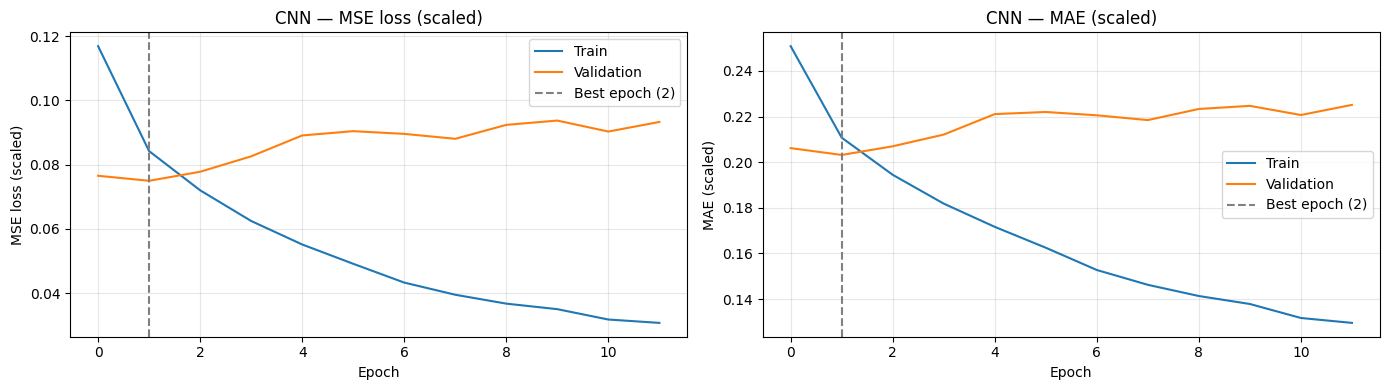

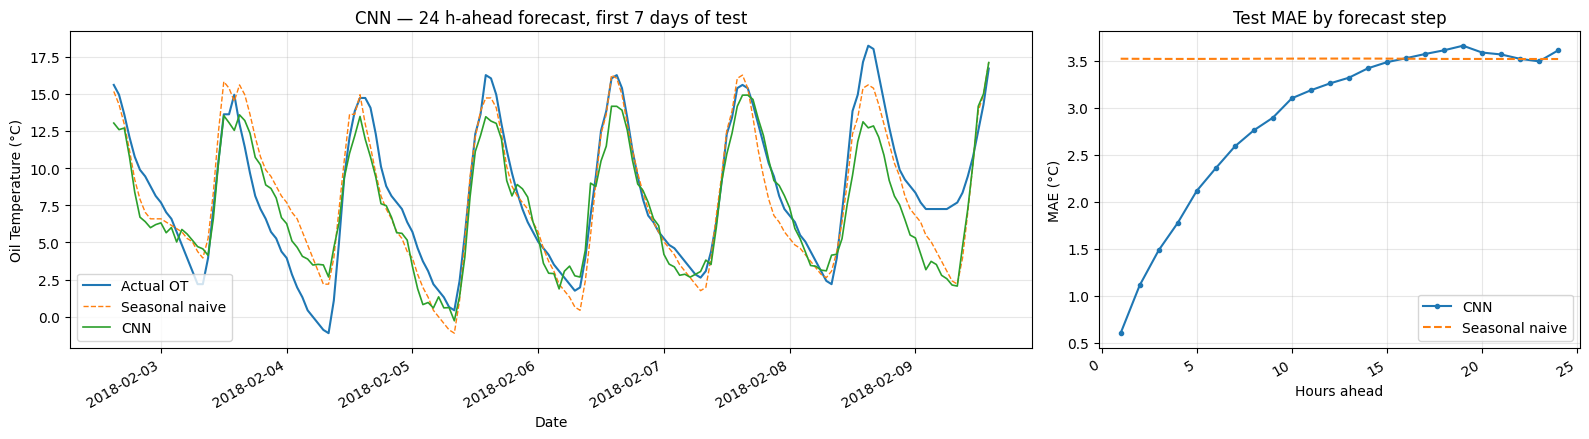

In [14]:
# CNN learning curves and test forecasts.
plot_learning_curves(cnn_hist, 'CNN')
plot_forecasts(cnn_test_pred, 'CNN')

#### MLP vs CNN

Both models beat the seasonal naive baseline by about the same amount. The MLP got 2.85 °C test MAE and the CNN got 2.90 °C, compared to 3.52 °C for the seasonal naive. We'd call them basically tied on accuracy. The difference shows up in cost and training behaviour. The CNN took longer to train (9 s vs 26 s) and twice as long to make predictions, and it started overfitting after only 2 epochs, while the MLP kept improving until epoch 6. Most of the CNN's parameters are in the dense layer after Flatten, not the conv layers, which is likely why it overfits faster.

Both models also fail in the same way. They do much better than the seasonal naive for the first ~15 hours, but past about 16 hours ahead they're no better than just copying yesterday.

#### Best Model Tuning

The MLP had the lowest validation MAE of the two neural models, so it's the one we tuned. We grid searched three hyperparameters, giving 3 × 3 × 2 = 18 runs:

| Hyperparameter | Values tried | Why |
|----------------|--------------|-----|
| Hidden layers | (64,), (128, 64), (256, 128) | Going from a smaller one-layer net up to a wider two-layer net |
| Dropout | 0.1, 0.2, 0.3 | The original MLP started overfitting around epoch 6 |
| Learning rate | 1e-3, 3e-4 | A slower rate might find a better minimum before early stopping kicks in |

Batch size stayed at 64 and everything else matches the original MLP: same windows, MSE loss, Adam, seed, and early stopping on validation loss (patience 10, best weights restored). The original config (128, 64) / 0.2 / 1e-3 is part of the grid, so the tuned model can't do worse than it on validation. Configs are ranked by **validation MAE only**. We don't look at the test set until the best config has been picked.

In [15]:
# Hyperparameter grid for the MLP. Original config is (128, 64), 0.2, 1e-3, 64.
MLP_GRID = {
    'hidden': [(64,), (128, 64), (256, 128)],
    'dropout': [0.1, 0.2, 0.3],
    'lr': [1e-3, 3e-4],
    'batch_size': [64],
}

grid_configs = [dict(zip(MLP_GRID, values)) for values in itertools.product(*MLP_GRID.values())]
grid_rows = []
best_val_mae, best_run = np.inf, None
grid_start = time.perf_counter()

for i, config in enumerate(grid_configs, start=1):
    model, hist, train_time = fit_model(build_mlp, **config)
    val_scores = score(y_val, model(X_val, training=False).numpy())
    grid_rows.append({
        **config,
        'Params': model.count_params(),
        'Epochs': len(hist.history['loss']),
        'Best epoch': int(np.argmin(hist.history['val_loss'])) + 1,
        'Train time (s)': train_time,
        'Val MAE': val_scores['MAE'],
        'Val RMSE': val_scores['RMSE'],
    })
    print(f"[{i:2d}/{len(grid_configs)}] hidden={str(config['hidden']):10} dropout={config['dropout']}  "
          f"lr={config['lr']:.0e}  ->  val MAE {val_scores['MAE']:.3f} °C  ({train_time:.1f} s)")

    # Only keep the best model around so we don't have to retrain it after.
    if val_scores['MAE'] < best_val_mae:
        best_val_mae = val_scores['MAE']
        best_run = (config, model, hist, train_time)

grid_time = time.perf_counter() - grid_start
print(f'\nGrid search finished: {len(grid_configs)} runs in {grid_time / 60:.1f} min')

grid_results = pd.DataFrame(grid_rows).sort_values('Val MAE').reset_index(drop=True)
grid_results.index += 1   # rank 1 = best
display(grid_results.round({'Train time (s)': 1, 'Val MAE': 3, 'Val RMSE': 3}))

[ 1/18] hidden=(64,)      dropout=0.1  lr=1e-03  ->  val MAE 2.398 °C  (3.6 s)


[ 2/18] hidden=(64,)      dropout=0.1  lr=3e-04  ->  val MAE 2.475 °C  (4.7 s)


[ 3/18] hidden=(64,)      dropout=0.2  lr=1e-03  ->  val MAE 2.383 °C  (3.3 s)


[ 4/18] hidden=(64,)      dropout=0.2  lr=3e-04  ->  val MAE 2.433 °C  (4.0 s)


[ 5/18] hidden=(64,)      dropout=0.3  lr=1e-03  ->  val MAE 2.336 °C  (3.5 s)


...

[15/18] hidden=(256, 128) dropout=0.2  lr=1e-03  ->  val MAE 2.408 °C  (3.7 s)


[16/18] hidden=(256, 128) dropout=0.2  lr=3e-04  ->  val MAE 2.406 °C  (5.9 s)


[17/18] hidden=(256, 128) dropout=0.3  lr=1e-03  ->  val MAE 2.361 °C  (5.9 s)


[18/18] hidden=(256, 128) dropout=0.3  lr=3e-04  ->  val MAE 2.380 °C  (6.8 s)

Grid search finished: 18 runs in 1.4 min


,hidden,dropout,lr,batch_size,Params,Epochs,Best epoch,Train time (s),Val MAE,Val RMSE
1,"(64,)",0.3,0.0010,64,44632,24,14,3.5,2.336,3.183
2,"(128, 64)",0.3,0.0010,64,95960,26,16,5.1,2.358,3.192
3,"(256, 128)",0.3,0.0010,64,208280,21,11,5.9,2.361,3.202
4,"(128, 64)",0.2,0.0010,64,95960,16,6,3.3,2.376,3.223
5,"(256, 128)",0.3,0.0003,64,208280,26,16,6.8,2.380,3.238
6,"(64,)",0.3,0.0003,64,44632,42,32,5.8,2.381,3.248
7,"(64,)",0.2,0.0010,64,44632,22,12,3.3,2.383,3.246
8,"(128, 64)",0.3,0.0003,64,95960,34,24,6.6,2.386,3.235
9,"(64,)",0.1,0.0010,64,44632,25,15,3.6,2.398,3.275
10,"(128, 64)",0.2,0.0003,64,95960,23,13,4.4,2.400,3.254


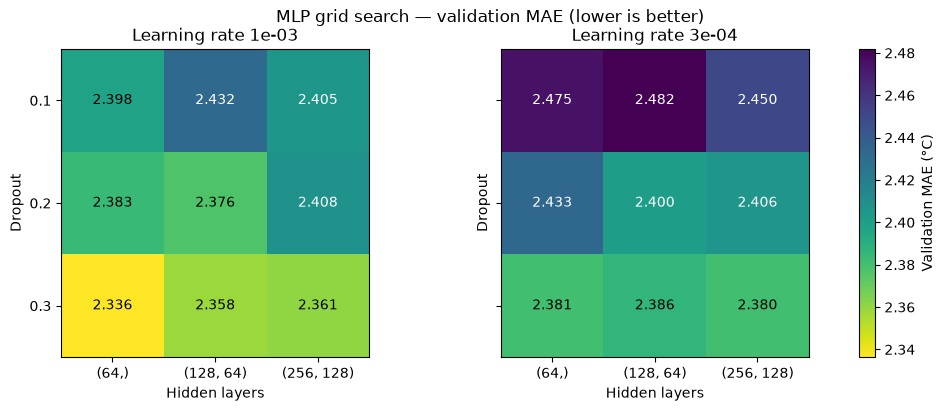

In [16]:
# Validation MAE for every config, one panel per learning rate.
fig, axes = plt.subplots(1, len(MLP_GRID['lr']), figsize=(13, 4), sharey=True)

for ax, lr in zip(axes, MLP_GRID['lr']):
    subset = grid_results[grid_results['lr'] == lr]
    table = subset.pivot_table(index='dropout', columns=subset['hidden'].astype(str), values='Val MAE')
    table = table[[str(h) for h in MLP_GRID['hidden']]]
    im = ax.imshow(table.values, cmap='viridis_r', vmin=grid_results['Val MAE'].min(),
                   vmax=grid_results['Val MAE'].max())
    for (r, c), val in np.ndenumerate(table.values):
        ax.text(c, r, f'{val:.3f}', ha='center', va='center',
                color='white' if val > grid_results['Val MAE'].median() else 'black')
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set(title=f'Learning rate {lr:.0e}', xlabel='Hidden layers', ylabel='Dropout')

fig.colorbar(im, ax=axes, label='Validation MAE (°C)')
fig.suptitle('MLP grid search — validation MAE (lower is better)')
plt.show()

Best config: {'hidden': (64,), 'dropout': 0.3, 'lr': 0.001, 'batch_size': 64}
Original MLP val MAE: 2.376 °C  |  Tuned MLP val MAE: 2.336 °C


,Params,Epochs,Train time (s),Inference (ms/window),Val MAE,Val RMSE,Test MAE,Test RMSE,Val MAE gain vs SN (%),Test MAE gain vs SN (%)
Model,,,,,,,,,,
Seasonal naive (24 h),0,NaN,0.000,0.000,2.816,3.807,3.520,4.770,0.000,0.000
Train mean,1,NaN,0.000,0.000,11.359,13.575,8.963,11.074,-303.435,-154.607
MLP,95960,16.0,3.247,0.008,2.376,3.223,2.848,4.016,15.597,19.090
CNN,111384,12.0,6.187,0.015,2.437,3.281,2.891,4.032,13.432,17.864
MLP (tuned),44632,24.0,3.464,0.009,2.336,3.183,2.832,3.971,17.019,19.552


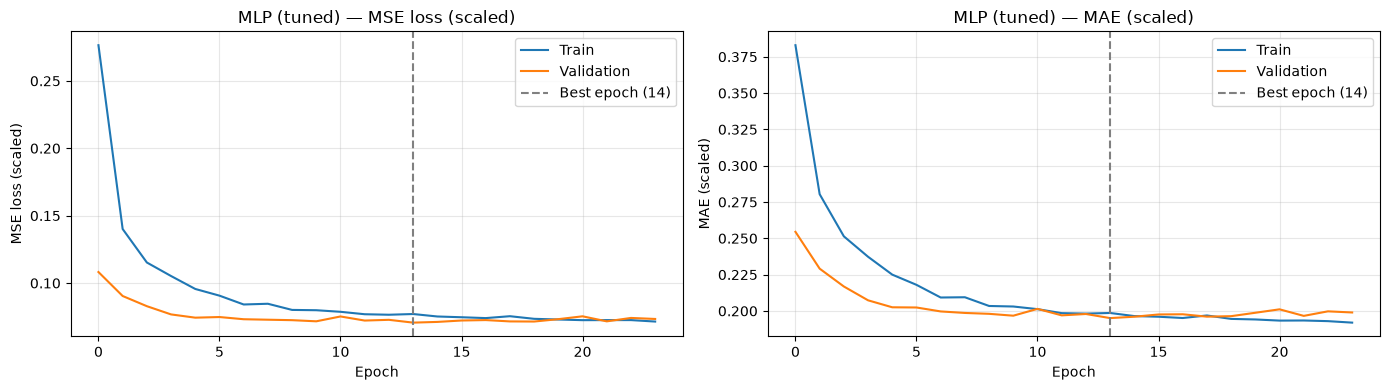

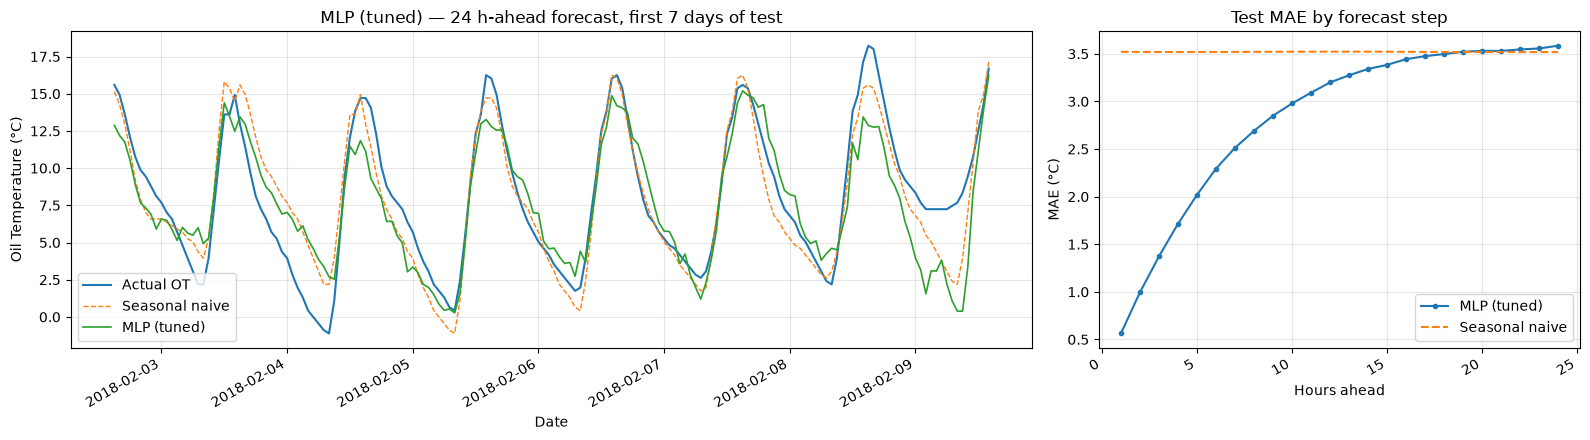

In [17]:
# The best run is already trained, so we just evaluate it on val and test.
best_config, mlp_tuned, mlp_tuned_hist, mlp_tuned_time = best_run
print('Best config:', best_config)
print(f"Original MLP val MAE: {comparison_table().loc['MLP', 'Val MAE']:.3f} °C  |  "
      f"Tuned MLP val MAE: {best_val_mae:.3f} °C")

mlp_tuned_val_pred, mlp_tuned_test_pred = evaluate_model('MLP (tuned)', mlp_tuned, mlp_tuned_hist, mlp_tuned_time)
display(comparison_table())

plot_learning_curves(mlp_tuned_hist, 'MLP (tuned)')
plot_forecasts(mlp_tuned_test_pred, 'MLP (tuned)')

#### Grid Search Results

The best config was a single hidden layer of 64 units with dropout 0.3 and a learning rate of 1e-3. It brought validation MAE down from 2.376 °C to 2.336 °C. On the test set, which we only checked after picking the config, it got 2.832 °C compared to 2.848 °C for the original MLP. That's a 19.6% improvement over the seasonal naive, and it uses less than half the parameters (44,632 vs 95,960).

What the grid showed:
- **Dropout mattered the most.** The top three configs all use 0.3, and for every hidden size and learning rate, 0.3 did better than 0.1. This lines up with the original MLP overfitting early.
- **1e-3 beat 3e-4 in 8 of the 9 pairs.** The slower learning rate trained for more epochs but still ended up worse.
- **Model size barely mattered.** At dropout 0.3 and lr 1e-3, all three sizes landed within 0.025 °C of each other, so the smallest network is enough.

To be honest, the gain is small. The whole grid only spans 2.336 to 2.482 °C, and every run used a single seed, so a 0.04 °C improvement could just be run-to-run noise. Tuning also didn't fix the main weakness. The tuned MLP still loses its edge over the seasonal naive after about 19 hours ahead. Before trusting the ranking we'd want to rerun the top few configs with a few different seeds.

### Stage 2 - Advanced Models


### Stage 3 - Transformer Architecture Implementation


### Jetson Deployment (Optional)